In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

In [3]:
test_df = pd.read_csv("../data/testing.csv")

# Remove rows with missing target values
test_df = test_df.dropna(subset=["Churn"]).copy()

# Separate features and target
X_test = test_df.drop(columns=["CustomerID", "Churn"])
y_test = test_df["Churn"].astype(int)

print("Test dataset shape:", test_df.shape)

print("\nTarget distribution:")
print(y_test.value_counts())

print("\nTarget percentage:")
print(y_test.value_counts(normalize=True) * 100)

Test dataset shape: (64374, 12)

Target distribution:
Churn
0    33881
1    30493
Name: count, dtype: int64

Target percentage:
Churn
0    52.631497
1    47.368503
Name: proportion, dtype: float64


In [4]:
decision_tree_model = joblib.load("../models/decision_tree.pkl")
random_forest_model = joblib.load("../models/random_forest.pkl")
gradient_boosting_model = joblib.load("../models/gradient_boosting.pkl")

models = {
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

print("All trained models loaded successfully!")

All trained models loaded successfully!


In [5]:
results = []
predictions = {}
probabilities = {}

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

test_results = pd.DataFrame(results)

print(test_results.round(4))

               Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0      Decision Tree    0.5033     0.4881  0.9987    0.6557   0.5281
1      Random Forest    0.5041     0.4886  0.9987    0.6561   0.6248
2  Gradient Boosting    0.5062     0.4896  0.9983    0.6570   0.7176


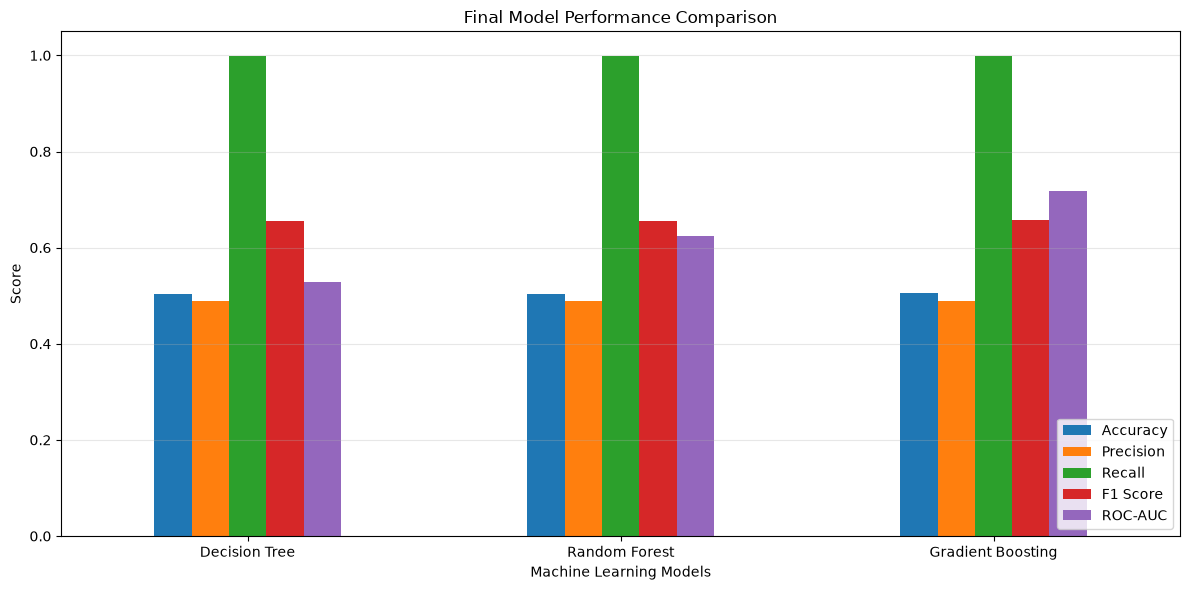

In [6]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

test_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05)
)

plt.title("Final Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

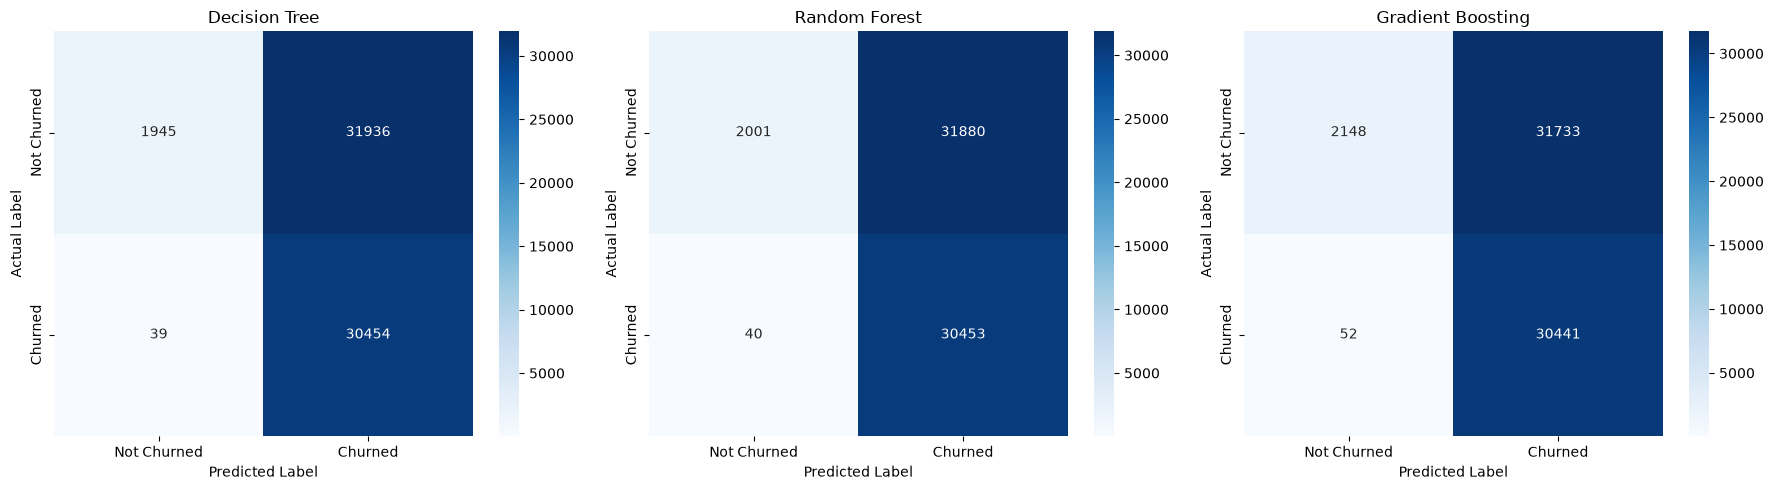

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Not Churned", "Churned"],
        yticklabels=["Not Churned", "Churned"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

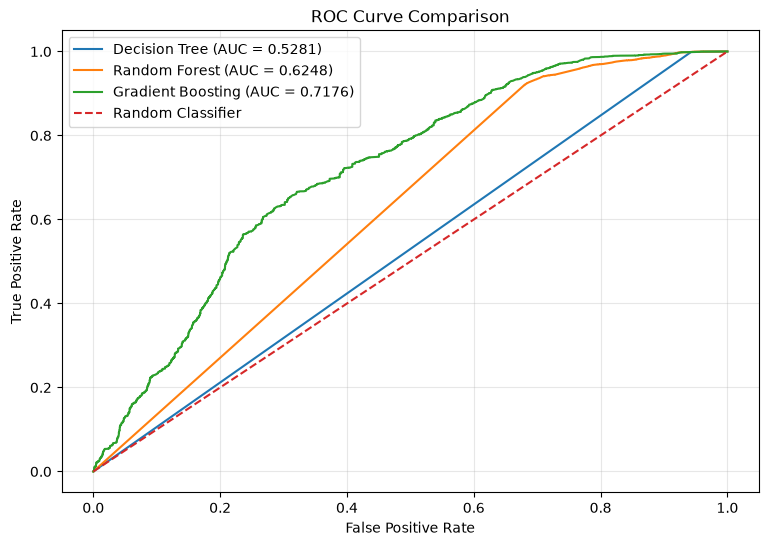

In [8]:
plt.figure(figsize=(9, 6))

for name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [10]:
train_df = pd.read_csv("../data/training.csv")
test_df = pd.read_csv("../data/testing.csv")

train_df = train_df.dropna(subset=["Churn"]).copy()
test_df = test_df.dropna(subset=["Churn"]).copy()

print("TRAIN DATA")
print("Shape:", train_df.shape)
print("Churn distribution:")
print(train_df["Churn"].value_counts(normalize=True))

print("\nTEST DATA")
print("Shape:", test_df.shape)
print("Churn distribution:")
print(test_df["Churn"].value_counts(normalize=True))

TRAIN DATA
Shape: (440832, 12)
Churn distribution:
Churn
1.0    0.567107
0.0    0.432893
Name: proportion, dtype: float64

TEST DATA
Shape: (64374, 12)
Churn distribution:
Churn
0    0.526315
1    0.473685
Name: proportion, dtype: float64


In [11]:
numerical_features = [
    "Age",
    "Tenure",
    "Usage Frequency",
    "Support Calls",
    "Payment Delay",
    "Total Spend",
    "Last Interaction"
]

train_summary = train_df[numerical_features].describe().T
test_summary = test_df[numerical_features].describe().T

comparison = pd.DataFrame({
    "Train Mean": train_summary["mean"],
    "Test Mean": test_summary["mean"],
    "Train Std": train_summary["std"],
    "Test Std": test_summary["std"],
    "Train Min": train_summary["min"],
    "Test Min": test_summary["min"],
    "Train Max": train_summary["max"],
    "Test Max": test_summary["max"]
})

print(comparison.round(2))

                  Train Mean  Test Mean  Train Std  Test Std  Train Min  \
Age                    39.37      41.97      12.44     13.92       18.0   
Tenure                 31.26      31.99      17.26     17.10        1.0   
Usage Frequency        15.81      15.08       8.59      8.82        1.0   
Support Calls           3.60       5.40       3.07      3.11        0.0   
Payment Delay          12.97      17.13       8.26      8.85        0.0   
Total Spend           631.62     541.02     240.80    260.87      100.0   
Last Interaction       14.48      15.50       8.60      8.64        1.0   

                  Test Min  Train Max  Test Max  
Age                   18.0       65.0      65.0  
Tenure                 1.0       60.0      60.0  
Usage Frequency        1.0       30.0      30.0  
Support Calls          0.0       10.0      10.0  
Payment Delay          0.0       30.0      30.0  
Total Spend          100.0     1000.0    1000.0  
Last Interaction       1.0       30.0      30.0  

In [12]:
categorical_features = [
    "Gender",
    "Subscription Type",
    "Contract Length"
]

for col in categorical_features:

    print(f"\n{'=' * 40}")
    print(col)
    print("=" * 40)

    print("\nTRAIN:")
    print(train_df[col].value_counts(normalize=True).round(4))

    print("\nTEST:")
    print(test_df[col].value_counts(normalize=True).round(4))


Gender

TRAIN:
Gender
Male      0.5677
Female    0.4323
Name: proportion, dtype: float64

TEST:
Gender
Female    0.5336
Male      0.4664
Name: proportion, dtype: float64

Subscription Type

TRAIN:
Subscription Type
Standard    0.3383
Premium     0.3373
Basic       0.3244
Name: proportion, dtype: float64

TEST:
Subscription Type
Standard    0.3340
Basic       0.3332
Premium     0.3328
Name: proportion, dtype: float64

Contract Length

TRAIN:
Contract Length
Annual       0.4020
Quarterly    0.4004
Monthly      0.1976
Name: proportion, dtype: float64

TEST:
Contract Length
Monthly      0.3438
Annual       0.3326
Quarterly    0.3236
Name: proportion, dtype: float64


In [13]:
for name, y_pred in predictions.items():

    print(f"\n{name}")

    print("Actual distribution:")
    print(y_test.value_counts(normalize=True).round(4))

    print("\nPredicted distribution:")
    print(pd.Series(y_pred).value_counts(normalize=True).round(4))


Decision Tree
Actual distribution:
Churn
0    0.5263
1    0.4737
Name: proportion, dtype: float64

Predicted distribution:
1.0    0.9692
0.0    0.0308
Name: proportion, dtype: float64

Random Forest
Actual distribution:
Churn
0    0.5263
1    0.4737
Name: proportion, dtype: float64

Predicted distribution:
1.0    0.9683
0.0    0.0317
Name: proportion, dtype: float64

Gradient Boosting
Actual distribution:
Churn
0    0.5263
1    0.4737
Name: proportion, dtype: float64

Predicted distribution:
1.0    0.9658
0.0    0.0342
Name: proportion, dtype: float64


In [14]:
features = [
    "Age",
    "Tenure",
    "Usage Frequency",
    "Support Calls",
    "Payment Delay",
    "Total Spend",
    "Last Interaction"
]

print("TRAIN DATA — GROUPED BY CHURN")
print(train_df.groupby("Churn")[features].mean().round(2))

print("\nTEST DATA — GROUPED BY CHURN")
print(test_df.groupby("Churn")[features].mean().round(2))

TRAIN DATA — GROUPED BY CHURN
         Age  Tenure  Usage Frequency  Support Calls  Payment Delay  \
Churn                                                                 
0.0    36.26   32.28            16.26           1.59          10.02   
1.0    41.75   30.47            15.46           5.14          15.22   

       Total Spend  Last Interaction  
Churn                                 
0.0         749.95             13.01  
1.0         541.29             15.60  

TEST DATA — GROUPED BY CHURN
         Age  Tenure  Usage Frequency  Support Calls  Payment Delay  \
Churn                                                                 
0      41.13   28.83            16.04            4.5          12.45   
1      42.90   35.52            14.01            6.4          22.33   

       Total Spend  Last Interaction  
Churn                                 
0           560.54             15.52  
1           519.34             15.47  


In [15]:
categorical_features = [
    "Gender",
    "Subscription Type",
    "Contract Length"
]

for col in categorical_features:

    print(f"\n{'=' * 45}")
    print(col)
    print("=" * 45)

    print("\nTRAIN CHURN RATE:")
    print(
        train_df.groupby(col, observed=True)["Churn"]
        .mean().round(4)
    )

    print("\nTEST CHURN RATE:")
    print(
        test_df.groupby(col, observed=True)["Churn"]
        .mean().round(4)
    )


Gender

TRAIN CHURN RATE:
Gender
Female    0.6667
Male      0.4913
Name: Churn, dtype: float64

TEST CHURN RATE:
Gender
Female    0.5505
Male      0.3858
Name: Churn, dtype: float64

Subscription Type

TRAIN CHURN RATE:
Subscription Type
Basic       0.5818
Premium     0.5594
Standard    0.5607
Name: Churn, dtype: float64

TEST CHURN RATE:
Subscription Type
Basic       0.4828
Premium     0.4650
Standard    0.4733
Name: Churn, dtype: float64

Contract Length

TRAIN CHURN RATE:
Contract Length
Annual       0.4608
Monthly      1.0000
Quarterly    0.4603
Name: Churn, dtype: float64

TEST CHURN RATE:
Contract Length
Annual       0.4622
Monthly      0.5161
Quarterly    0.4405
Name: Churn, dtype: float64


In [16]:
for name, y_prob in probabilities.items():

    print(f"\n{name}")

    print(pd.Series(y_prob).describe().round(4))

    print(
        "Predictions above 0.5:",
        (y_prob >= 0.5).mean() * 100,
        "%"
    )


Decision Tree
count    64374.0000
mean         0.9692
std          0.1728
min          0.0000
25%          1.0000
50%          1.0000
75%          1.0000
max          1.0000
dtype: float64
Predictions above 0.5: 96.91801037686022 %

Random Forest
count    64374.0000
mean         0.9620
std          0.1732
min          0.0000
25%          1.0000
50%          1.0000
75%          1.0000
max          1.0000
dtype: float64
Predictions above 0.5: 96.82946531208252 %

Gradient Boosting
count    64374.0000
mean         0.9585
std          0.1757
min          0.0100
25%          0.9983
50%          0.9997
75%          0.9999
max          1.0000
dtype: float64
Predictions above 0.5: 96.58247118401839 %


In [17]:
print("TRAIN DATA")
print(pd.crosstab(
    train_df["Contract Length"],
    train_df["Churn"],
    normalize="index"
).round(4))

print("\nTEST DATA")
print(pd.crosstab(
    test_df["Contract Length"],
    test_df["Churn"],
    normalize="index"
).round(4))

TRAIN DATA
Churn               0.0     1.0
Contract Length                
Annual           0.5392  0.4608
Monthly          0.0000  1.0000
Quarterly        0.5397  0.4603

TEST DATA
Churn                 0       1
Contract Length                
Annual           0.5378  0.4622
Monthly          0.4839  0.5161
Quarterly        0.5595  0.4405


In [18]:
train_ids = set(train_df["CustomerID"])
test_ids = set(test_df["CustomerID"])

print("Training unique IDs:", len(train_ids))
print("Test unique IDs:", len(test_ids))

print("Overlapping IDs:", len(train_ids.intersection(test_ids)))

print("\nTraining ID range:")
print(train_df["CustomerID"].min(), train_df["CustomerID"].max())

print("\nTest ID range:")
print(test_df["CustomerID"].min(), test_df["CustomerID"].max())

Training unique IDs: 440832
Test unique IDs: 64374
Overlapping IDs: 62995

Training ID range:
2.0 449999.0

Test ID range:
1 64374


In [19]:
comparison = train_df.merge(
    test_df,
    on="CustomerID",
    suffixes=("_train", "_test")
)

print("Overlapping records:", len(comparison))

columns_to_compare = [
    "Age",
    "Gender",
    "Tenure",
    "Usage Frequency",
    "Support Calls",
    "Payment Delay",
    "Subscription Type",
    "Contract Length",
    "Total Spend",
    "Last Interaction",
    "Churn"
]

for col in columns_to_compare:

    match_count = (
        comparison[f"{col}_train"] ==
        comparison[f"{col}_test"]
    ).sum()

    match_percentage = match_count / len(comparison) * 100

    print(f"{col}: {match_percentage:.2f}% identical")

Overlapping records: 62995
Age: 2.10% identical
Gender: 50.02% identical
Tenure: 1.64% identical
Usage Frequency: 3.34% identical
Support Calls: 9.06% identical
Payment Delay: 3.20% identical
Subscription Type: 33.37% identical
Contract Length: 33.46% identical
Total Spend: 0.12% identical
Last Interaction: 3.38% identical
Churn: 47.97% identical


In [20]:
comparison["Complete_Match"] = (
    comparison[
        [f"{col}_train" for col in columns_to_compare]
    ].values ==
    comparison[
        [f"{col}_test" for col in columns_to_compare]
    ].values
).all(axis=1)

print(
    "Completely identical records:",
    comparison["Complete_Match"].sum()
)

print(
    "Completely different records:",
    (~comparison["Complete_Match"]).sum()
)

Completely identical records: 0
Completely different records: 62995
